## Levene's Test

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
#  Generate groups with same mean but different spreads
np.random.seed(42)

# Class A and B: same mean=70, same std=5 -> equal variances
group_A = np.random.normal(loc=70, scale=5, size=50)
group_B = np.random.normal(loc=72, scale=5, size=50)

# Class C: same mean=70 but std=12 -> unequal variance
group_C = np.random.normal(loc=70, scale=12, size=50)

# Build DataFrame for plotting
df = pd.DataFrame({
    "value": np.concatenate([group_A, group_B, group_C]),
    "group": ["A"]*50 + ["B"]*50 + ["C"]*50
})
print(df.groupby("group")["value"].agg(["mean", "std"]))

            mean        std
group                      
A      68.872630   4.668344
B      72.088904   4.371625
C      69.528549  12.184963


In [3]:
# Test H0: variances are equal
alpha = 0.05

# Case 1: A vs B should keep H0 (equal variances)
w1, p1 = stats.levene(group_A, group_B, center="median")
print(f"A vs B: W={w1:.3f}, p={p1:.4f} -> {'UNEQUAL' if p1 < alpha else 'equal, can use standard t-test'}")

# Case 2: A vs C should reject H0 (unequal variances)
w2, p2 = stats.levene(group_A, group_C, center="median")
print(f"A vs C: W={w2:.3f}, p={p2:.4f} -> {'UNEQUAL, use Welch t-test' if p2 < alpha else 'equal'}")

# Compare center=mean vs center=median
w_mean, p_mean = stats.levene(group_A, group_C, center="mean")
w_med, p_med = stats.levene(group_A, group_C, center="median")
print(f"center=mean: p={p_mean:.4f} | center=median (Brown-Forsythe): p={p_med:.4f}")

# What to do next: standard t vs Welch t for A vs C
t_std, p_std = stats.ttest_ind(group_A, group_C, equal_var=True)
t_welch, p_welch = stats.ttest_ind(group_A, group_C, equal_var=False)
print(f"Standard t: p={p_std:.4f} | Welch t: p={p_welch:.4f}")

A vs B: W=0.278, p=0.5990 -> equal, can use standard t-test
A vs C: W=27.663, p=0.0000 -> UNEQUAL, use Welch t-test
center=mean: p=0.0000 | center=median (Brown-Forsythe): p=0.0000
Standard t: p=0.7230 | Welch t: p=0.7234


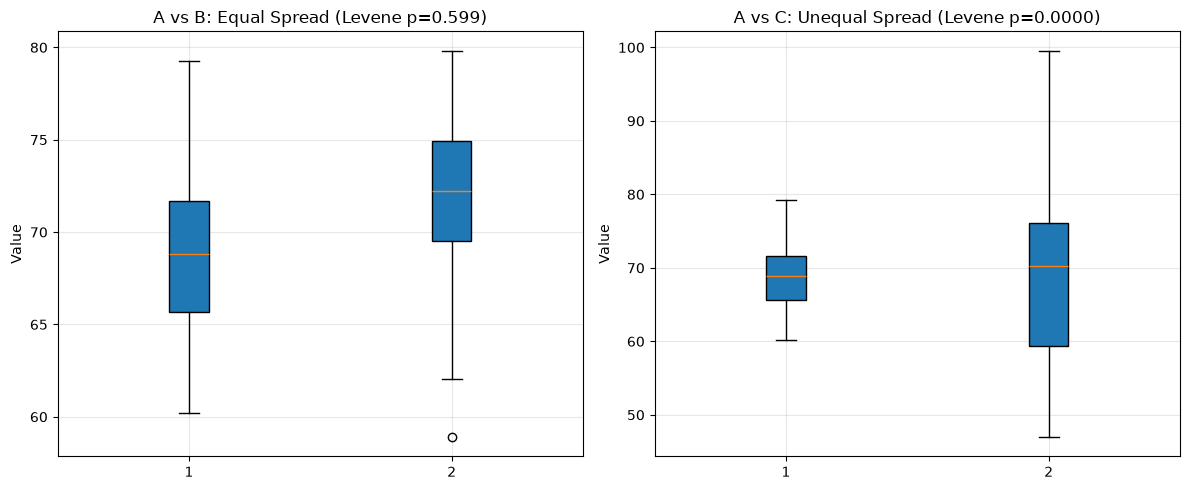

In [8]:
# Visualize spread difference with boxplots
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Left plot: A vs B with equal spread
ax[0].boxplot([group_A, group_B], label=["A (std=5)", "B (std=5)"], patch_artist=True)
ax[0].set_title(f"A vs B: Equal Spread (Levene p={p1:.3f})")
ax[0].set_ylabel("Value")
ax[0].grid(alpha=0.3)

# Right plot: A vs C with clearly different spread
ax[1].boxplot([group_A, group_C], label=["A (std=5)", "C (std=12)"], patch_artist=True)
ax[1].set_title(f"A vs C: Unequal Spread (Levene p={p2:.4f})")
ax[1].set_ylabel("Value")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
# Experiment - Levene (median) vs Bartlett on skewed data
# Skewed groups with same spread but non-normal shape
skew1 = np.random.lognormal(mean=3.0, sigma=0.4, size=60)
skew2 = np.random.lognormal(mean=3.0, sigma=0.4, size=60)

_, p_levene_skew = stats.levene(skew1, skew2, center="median")
_, p_bartlett_skew = stats.bartlett(skew1, skew2)
print(f"Skewed equal-spread: Levene p={p_levene_skew:.4f} | Bartlett p={p_bartlett_skew:.4f}")

# Add one extreme outlier to group B
group_B_out = np.append(group_B, [110])
_, p_after = stats.levene(group_A, group_B_out, center="median")
_, p_after_mean = stats.levene(group_A, group_B_out, center="mean")
print(f"After one outlier: median version p={p_after:.4f} | mean version p={p_after_mean:.4f}")

# Question: Which test falsely rejects on skewed data, Bartlett or Levene-median?
# Question: Which center resists the single outlier better, mean or median?

Skewed equal-spread: Levene p=0.9170 | Bartlett p=0.0436
After one outlier: median version p=0.6653 | mean version p=0.6350
